# Notebook n°5 : Comparaison des modèles

### Problématique

Dans quelle mesure la structure du réseau TGV est-elle associée à la régularité des liaisons, et peut-on exploiter cette structure pour améliorer la prédiction des retards ?

## 1. Objectifs

Nous comparons quatre modèles de Machine Learning sur **les mêmes observations** :

- **A : Baseline** : variables historiques du notebook 03.
- **B : Baseline + graphe** : variables historiques et centralités des gares.
- **C : Baseline + cluster** : variables historiques et cluster de la liaison (notebook 04).
- **D : Baseline + graphe + cluster** : combinaison des deux enrichissements.

Le modèle A reprend les variables, les hyperparamètres et les poids d'entraînement du notebook 03. Les variantes sont comparées sur la validation, puis réentraînées sur train + validation pour une évaluation finale sur le test.

## I. Préparation des données

Nous reprenons le même ETL, la même fenêtre historique de 12 mois et **la même séparation chronologique** que dans le notebook 03.

Le clustering du notebook 04 a été appris uniquement sur l'entraînement. Une liaison inconnue reçoit le code `-1` : elle n'est pas supprimée de l'évaluation.

Pour éviter une fuite temporelle, les métriques du graphe sont calculées **uniquement à partir des liaisons connues pendant l'entraînement**. Pour le test final, le graphe est recalculé sur train + validation, jamais sur le test.

In [35]:
"""Charger les données et les fonctions communes aux notebooks 03 à 05."""

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "src"))

from projet_kit_data.ml.baseline import (
    BASELINE_FEATURES,
    BASELINE_NUMERIC_FEATURES,
    build_baseline_dataset,
    chronological_split,
    prepare_baseline_data,
    predict_historical_naive,
)
from projet_kit_data.ml.evaluation import compute_metrics
from projet_kit_data.ml.models import build_model
from projet_kit_data.comparaison import (
    add_cluster_to_dataset,
    load_cluster_features,
)
from projet_kit_data.graph.network import build_railway_graph
from projet_kit_data.graph.centrality import compute_graph_features

# Les mêmes données et la même préparation que dans le notebook 03.
data_etl = pd.read_parquet(project_root / "data" / "processed" / "sncf.parquet")
data_ml = prepare_baseline_data(data_etl)
dataset = build_baseline_dataset(data_ml, window_months=12)

train, validation, test = chronological_split(
    dataset, train_fraction=0.70, validation_fraction=0.15
)

assert train["date"].max() < validation["date"].min()
assert validation["date"].max() < test["date"].min()

for nom, frame in (("Train", train), ("Validation", validation), ("Test", test)):
    print(f"{nom} : {len(frame)} observations, "
          f"du {frame['date'].min().date()} au {frame['date'].max().date()}")

Train : 7844 observations, du 2019-01-01 au 2024-05-01
Validation : 1571 observations, du 2024-06-01 au 2025-06-01
Test : 1857 observations, du 2025-07-01 au 2026-09-01


In [36]:
# Charger les clusters du notebook 04, appris sur la période d'entraînement.
clusters = load_cluster_features(
    project_root / "data" / "processed" / "clusters_liaisons.csv"
)
assert not clusters.duplicated(["gare_a", "gare_b"]).any()

# Une liaison inconnue reste dans le dataset, avec le code -1.
def ajouter_clusters(frame):
    enrichi = add_cluster_to_dataset(frame, clusters)
    assert len(enrichi) == len(frame), "La jointure des clusters a modifié le nombre de lignes."
    enrichi["cluster"] = enrichi["cluster"].fillna(-1).astype(int)
    return enrichi

train = ajouter_clusters(train)
validation = ajouter_clusters(validation)
test = ajouter_clusters(test)

for nom, frame in (("Train", train), ("Validation", validation), ("Test", test)):
    print(f"{nom} : {(frame['cluster'] == -1).sum()} observations sans cluster connu")

Train : 0 observations sans cluster connu
Validation : 0 observations sans cluster connu
Test : 0 observations sans cluster connu


In [37]:
# Construire les caractéristiques du graphe à partir d'une période passée.
# Aucun mois de validation/test n'entre dans la construction du graphe.
GRAPH_FEATURES = [
    f"{prefix}_{metric}"
    for prefix in ("depart", "arrivee")
    for metric in ("in_degree", "out_degree", "total_degree", "betweenness", "pagerank")
]


def ajouter_graphe(reference, *ensembles):
    """Calculer le graphe sur reference, puis enrichir les ensembles demandés."""
    # Chaque liaison orientée déjà connue représente une arête.
    routes = reference[["departure", "arrival"]].drop_duplicates().copy()
    routes["planned"] = 1
    graphe = build_railway_graph(routes)
    gares = compute_graph_features(graphe).set_index("station")

    resultats = []
    for frame in ensembles:
        enrichi = frame.copy()
        for prefix, colonne in (("depart", "departure"), ("arrivee", "arrival")):
            for metric in ("in_degree", "out_degree", "total_degree", "betweenness", "pagerank"):
                enrichi[f"{prefix}_{metric}"] = (
                    enrichi[colonne].map(gares[metric]).fillna(0.0)
                )
        resultats.append(enrichi)
    return tuple(resultats)

# Première version du graphe : entraînement seulement, pour la validation.
train_val, validation_val = ajouter_graphe(train, train, validation)
print("Caractéristiques du graphe :", len(GRAPH_FEATURES))

Caractéristiques du graphe : 10


## II. Comparaison sur la validation

Nous conservons les paramètres sélectionnés dans le notebook 03 (`max_iter=100`, `learning_rate=0.05`, `max_leaf_nodes=10`) **pour les quatre modèles**. Seules les variables explicatives changent : cela permet d'isoler l'apport du graphe et des clusters.

Nous entraînons chaque modèle sur le train uniquement, avec une pondération par le nombre de trains ayant circulé. Nous comparons ensuite la MAE, la RMSE et la MAE pondérée sur la validation. Le test n'est pas utilisé à ce stade.

In [38]:
# Variables communes et enrichissements étudiés.
BASE_FEATURES = BASELINE_FEATURES.copy()
HISTORIC_FEATURES = BASELINE_NUMERIC_FEATURES.copy()
CLUSTER_FEATURES = ["cluster"]
TARGET = "delay_rate_15"

configurations = {
    "A - Baseline": [],
    "B - Baseline + graphe": GRAPH_FEATURES,
    "C - Baseline + cluster": CLUSTER_FEATURES,
    "D - Baseline + graphe + cluster": GRAPH_FEATURES + CLUSTER_FEATURES,
}


def entrainer_modele(train_data, autres_variables):
    """Entraîner le même modèle que dans le notebook 03."""
    variables_numeriques = BASELINE_NUMERIC_FEATURES + autres_variables
    variables = BASELINE_FEATURES + autres_variables
    modele = build_model(
        numeric_features=variables_numeriques,
        max_iter=100,
        learning_rate=0.05,
        max_leaf_nodes=10,
    )
    modele.fit(
        train_data[variables],
        train_data[TARGET],
        regressor__sample_weight=train_data["circulated"],
    )
    return modele


def evaluer(modele, frame, autres_variables):
    """Mesurer les mêmes erreurs que dans le notebook 03."""
    prediction = modele.predict(frame[BASELINE_FEATURES + autres_variables]).clip(0, 1)
    scores = compute_metrics(frame[TARGET], prediction, frame["circulated"])
    scores["r2"] = r2_score(frame[TARGET], prediction)
    return scores, prediction

print("Train :", len(train_val), "| Validation :", len(validation_val))

Train : 7844 | Validation : 1571


In [39]:
# Évaluer les quatre configurations sur la validation, sans regarder le test.
modeles_validation = {}
resultats_validation = []

for nom, extras in configurations.items():
    modele = entrainer_modele(train_val, extras)
    scores, _ = evaluer(modele, validation_val, extras)
    modeles_validation[nom] = modele
    resultats_validation.append({"modele": nom, **scores})

validation_results = pd.DataFrame(resultats_validation).set_index("modele")
display((validation_results[["mae", "rmse", "weighted_mae"]] * 100).round(3))

# Le choix du modèle est fait exclusivement avec la MAE pondérée de validation.
modele_retenu = validation_results["weighted_mae"].idxmin()
print("Modèle retenu sur la validation :", modele_retenu)

,mae,rmse,weighted_mae
modele,,,
A - Baseline,2.960,4.347,2.478
B - Baseline + graphe,2.967,4.356,2.484
C - Baseline + cluster,2.960,4.355,2.482
D - Baseline + graphe + cluster,2.959,4.352,2.483


Modèle retenu sur la validation : A - Baseline


## III. Évaluation finale sur le test

Après la comparaison sur la validation, nous réentraînons les quatre configurations sur **train + validation**. Le graphe est recalculé sur cette période uniquement ; les clusters restent ceux appris dans le notebook 04, sans utiliser les données du test.

Nous présentons les quatre résultats finaux pour étudier l'apport des variables. **Le modèle retenu reste celui choisi sur la validation** : il ne doit pas être remplacé par celui qui obtient le meilleur résultat sur le test.

Les métriques principales sont la MAE, la RMSE et la MAE pondérée ; le R² est conservé à titre complémentaire.

In [40]:
# Regrouper train + validation, comme dans le notebook 03.
train_final = pd.concat([train, validation], ignore_index=True)
train_final, test_final = ajouter_graphe(train_final, train_final, test)

assert train_final["date"].max() < test_final["date"].min()
assert len(test_final) == len(test)

resultats = []
modeles_finaux = {}
predictions_finales = {}

for nom, extras in configurations.items():
    modele = entrainer_modele(train_final, extras)
    scores, prediction = evaluer(modele, test_final, extras)
    modeles_finaux[nom] = modele
    predictions_finales[nom] = prediction
    resultats.append({"modele": nom, **scores})

# Tous les modèles sont évalués sur les mêmes observations du test.
resultats_test = pd.DataFrame(resultats).set_index("modele")
tableau = resultats_test.copy()
for colonne in ("mae", "rmse", "weighted_mae"):
    tableau[colonne] *= 100

tableau = tableau.rename(columns={
    "mae": "mae_pts", "rmse": "rmse_pts", "weighted_mae": "mae_ponderee_pts"
})
display(tableau.round(3))
print("Modèle sélectionné AVANT le test :", modele_retenu)

,mae_pts,rmse_pts,mae_ponderee_pts,r2
modele,,,,
A - Baseline,4.373,6.907,3.729,0.433
B - Baseline + graphe,4.368,6.907,3.723,0.433
C - Baseline + cluster,4.368,6.918,3.726,0.431
D - Baseline + graphe + cluster,4.371,6.911,3.731,0.432


Modèle sélectionné AVANT le test : A - Baseline


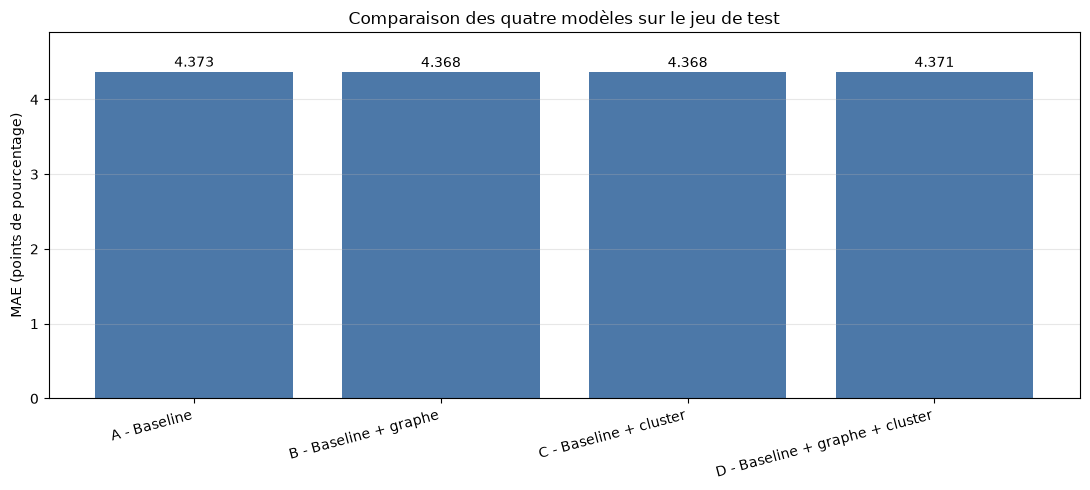

In [41]:

%matplotlib inline

import matplotlib.pyplot as plt

# Comparer la MAE des quatre modèles sur le jeu de test.
fig, ax = plt.subplots(figsize=(11, 5))
valeurs = tableau["mae_pts"]

ax.bar(range(len(valeurs)), valeurs, color="#4c78a8")

ax.set_xticks(range(len(valeurs)))
ax.set_xticklabels(valeurs.index, rotation=15, ha="right")
ax.set_ylabel("MAE (points de pourcentage)")
ax.set_title("Comparaison des quatre modèles sur le jeu de test")
ax.grid(axis="y", alpha=0.3)

# Afficher les valeurs au-dessus de chaque barre.
for i, valeur in enumerate(valeurs):
    ax.text(
        i,
        valeur + max(valeurs) * 0.015,
        f"{valeur:.3f}",
        ha="center",
    )

ax.set_ylim(0, max(valeurs) * 1.12)

plt.tight_layout()
plt.show()


In [42]:
# Comparer au véritable modèle naïf du notebook 03 : historique par liaison.
naive_test = predict_historical_naive(train_final, test_final)
scores_naifs = compute_metrics(test_final[TARGET], naive_test, test_final["circulated"])
scores_naifs["r2"] = r2_score(test_final[TARGET], naive_test)

comparaison_complete = pd.concat([
    pd.DataFrame([{"modele": "Naïf historique", **scores_naifs}]).set_index("modele"),
    resultats_test,
])

comparaison_affichage = comparaison_complete.copy()
comparaison_affichage[["mae", "rmse", "weighted_mae"]] *= 100
display(comparaison_affichage.round(3))

# Vérifier, si disponible, la cohérence avec les prédictions exportées par le 03.
chemin_baseline = project_root / "data" / "processed" / "ml" / "baseline_predictions_test.parquet"
if chemin_baseline.is_file():
    reference = pd.read_parquet(chemin_baseline)
    cles = ["date", "service", "departure", "arrival"]
    courant = test_final[cles].copy()
    courant["prediction_ml_05"] = predictions_finales["A - Baseline"]
    correspondance = courant.merge(
        reference[cles + ["prediction_ml"]],
        on=cles, how="outer", validate="one_to_one", indicator=True,
    )
    assert (correspondance["_merge"] == "both").all(), "Les tests 03 et 05 ne portent pas sur les mêmes lignes."
    ecart = (correspondance["prediction_ml_05"] - correspondance["prediction_ml"]).abs().max()
    print(f"Écart maximal entre la baseline A et le notebook 03 : {ecart:.10f}")
    assert np.isclose(ecart, 0, atol=1e-8), "Le modèle A ne reproduit pas la baseline du notebook 03."

,mae,rmse,weighted_mae,r2
modele,,,,
Naïf historique,4.443,6.457,3.930,0.504
A - Baseline,4.373,6.907,3.729,0.433
B - Baseline + graphe,4.368,6.907,3.723,0.433
C - Baseline + cluster,4.368,6.918,3.726,0.431
D - Baseline + graphe + cluster,4.371,6.911,3.731,0.432


Écart maximal entre la baseline A et le notebook 03 : 0.0000000000


## IV. Erreurs par cluster

Nous comparons les erreurs des quatre modèles au sein de chaque cluster du notebook 04. Le groupe `-1` correspond aux liaisons absentes de l'entraînement du clustering : ces observations restent dans le test afin de garder une comparaison équitable.

In [43]:
# Comparer les erreurs par cluster sur les mêmes observations du test.
performances = {}
for nom, prediction in predictions_finales.items():
    erreurs = test_final[["cluster", TARGET]].copy()
    erreurs["erreur_absolue"] = (erreurs[TARGET] - prediction).abs() * 100
    performances[nom] = erreurs.groupby("cluster")["erreur_absolue"].mean()

tableau_perf = pd.DataFrame(performances).sort_index()
display(tableau_perf.round(3))

,A - Baseline,B - Baseline + graphe,C - Baseline + cluster,D - Baseline + graphe + cluster
cluster,,,,
0,12.534,12.548,12.281,12.349
1,4.481,4.470,4.483,4.489
2,3.381,3.374,3.400,3.396
3,4.243,4.241,4.239,4.237


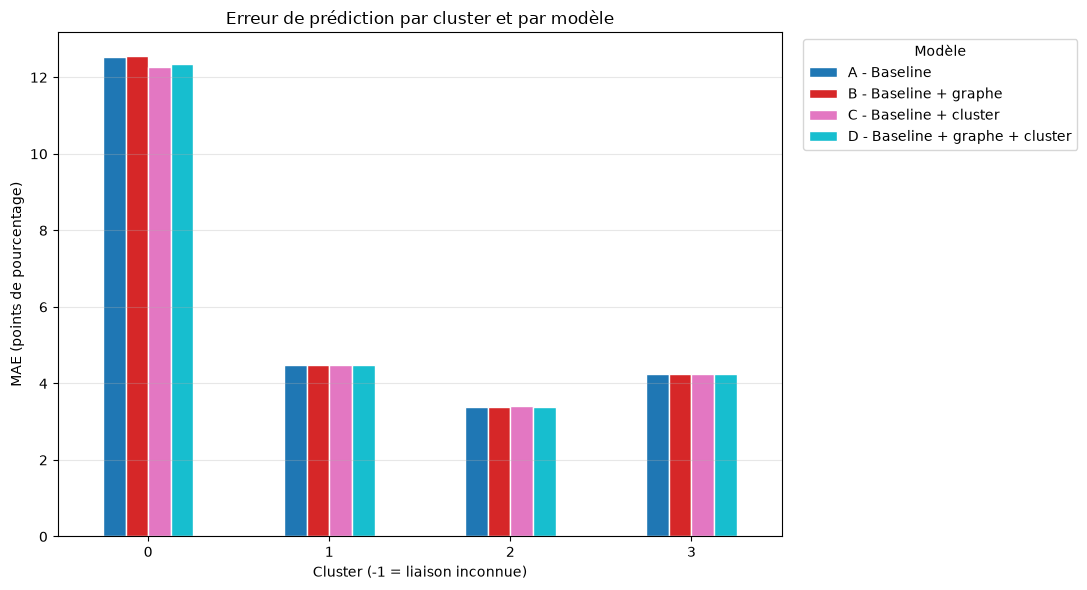

In [44]:
# Visualiser les différences entre modèles selon les clusters.
fig, ax = plt.subplots(figsize=(11, 6))
tableau_perf.plot(kind="bar", ax=ax, colormap="tab10", edgecolor="white")
ax.set_ylabel("MAE (points de pourcentage)")
ax.set_xlabel("Cluster (-1 = liaison inconnue)")
ax.set_title("Erreur de prédiction par cluster et par modèle")
ax.legend(title="Modèle", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.3)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.tight_layout()
plt.show()

## V. Bilan et interprétation

### 1. Résultats sur la validation : choix du modèle

Nous avons comparé les quatre modèles avec les mêmes observations et les mêmes paramètres d'entraînement. Seules les variables ajoutées (graphe et/ou cluster) changent.

| Modèle | MAE (pts) | RMSE (pts) | MAE pondérée (pts) |
|---|---:|---:|---:|
| **A — Baseline** | **2,960** | **4,347** | **2,478** |
| B — Baseline + graphe | 2,967 | 4,356 | 2,484 |
| C — Baseline + cluster | 2,960 | 4,355 | 2,482 |
| D — Baseline + graphe + cluster | 2,959 | 4,352 | 2,483 |

La **baseline A** obtient la plus faible MAE pondérée, qui est notre critère de sélection. Le modèle D a une MAE très légèrement inférieure (2,959 contre 2,960 point), mais cet écart est minime et ne change pas notre choix.

**Nous retenons donc le modèle A avant d'examiner le test.** Sur cette période de validation, l'ajout des informations de graphe ou de cluster ne montre pas d'amélioration convaincante.

### 2. Résultats sur le test : les enrichissements apportent-ils un gain ?

Après réentraînement sur *train + validation*, nous évaluons les quatre configurations sur les **1 857 mêmes observations** du test.

| Modèle | MAE (pts) | RMSE (pts) | MAE pondérée (pts) | R² |
|---|---:|---:|---:|---:|
| Naïf historique | 4,443 | **6,457** | 3,930 | **0,504** |
| **A — Baseline** | 4,373 | 6,907 | 3,729 | 0,433 |
| B — Baseline + graphe | **4,368** | **6,907** | **3,723** | **0,433** |
| C — Baseline + cluster | **4,368** | 6,918 | 3,726 | 0,431 |
| D — Baseline + graphe + cluster | 4,371 | 6,911 | 3,731 | 0,432 |

Les modèles B et C obtiennent une MAE légèrement plus faible que A. Le modèle B présente aussi la meilleure MAE pondérée du test, mais la différence avec A est de **0,006 point de pourcentage** (3,723 contre 3,729). Ce gain est trop faible pour conclure à une réelle amélioration de la prédiction. De plus, le modèle B **n'avait pas été retenu sur la validation** : nous ne changeons donc pas de modèle après avoir observé le test.

Le modèle D, qui combine graphe et cluster, ne fait pas mieux que la baseline A sur la MAE pondérée. **Ajouter davantage de variables ne garantit donc pas de meilleures prédictions.**

### 3. Comparaison avec le modèle naïf historique

Le modèle A réduit légèrement la MAE (4,373 contre 4,443 points) et la MAE pondérée (3,729 contre 3,930 points) par rapport au naïf historique. En revanche, le naïf conserve une **meilleure RMSE** (6,457 contre 6,907 points) et un **meilleur R²** (0,504 contre 0,433).

Cela montre que le modèle supervisé limite un peu mieux les erreurs moyennes, notamment en tenant compte du volume de trains, mais qu'il peut commettre **des erreurs importantes sur certaines observations**. Le modèle naïf reste donc une référence pertinente.

La vérification réalisée dans le code donne un écart maximal de **0,0000000000** entre les prédictions du modèle A et celles exportées par le notebook 03. Nous avons ainsi confirmé que les deux notebooks utilisent bien la même baseline.

### 4. Erreurs selon les clusters

| Cluster | MAE A (pts) | MAE B (pts) | MAE C (pts) | MAE D (pts) |
|---|---:|---:|---:|---:|
| 0 | 12,534 | 12,548 | **12,281** | 12,349 |
| 1 | 4,481 | **4,470** | 4,483 | 4,489 |
| 2 | 3,381 | **3,374** | 3,400 | 3,396 |
| 3 | 4,243 | 4,241 | 4,239 | **4,237** |

Les erreurs ne sont pas réparties de la même manière entre les clusters. **Le cluster 0 est nettement plus difficile à prédire**, avec une MAE d'environ 12 points, contre 3 à 4,5 points dans les autres groupes. Pour ce cluster, le modèle C apporte une amélioration par rapport à A, mais les erreurs restent élevées.

Cette comparaison doit cependant être interprétée avec prudence : les tableaux ne précisent pas ici **le nombre d'observations de test par cluster**. Un groupe peu représenté peut afficher une erreur moyenne plus instable. Les numéros des clusters ne correspondent pas à un classement de qualité : il faut se référer aux profils du notebook 04 pour comprendre leurs caractéristiques.

### 5. Conclusion par rapport à notre problématique

Nos résultats ne montrent **pas de gain prédictif net et robuste** lié à l'ajout des caractéristiques du graphe ou des clusters. Les différences observées entre les quatre modèles restent très faibles, et la configuration la plus simple est celle sélectionnée sur la validation.

Cela **ne signifie pas que la structure du réseau TGV n'a aucun lien avec la régularité**. Nous avons seulement montré que les indicateurs de graphe retenus ici (degrés, centralité d'intermédiarité et PageRank), ainsi que les clusters historiques, n'améliorent pas sensiblement ce modèle dans notre protocole actuel.

Plusieurs limites restent à garder en tête : le graphe est construit à partir des liaisons connues, sans pondération par le volume réel de trafic ; les clusters représentent des profils historiques fixes ; et les résultats reposent sur une seule séparation chronologique. D'autres représentations du réseau ou une validation temporelle répétée pourraient être étudiées ultérieurement.

**Pour l'application Streamlit, nous conservons donc le modèle A comme modèle final sélectionné**, tout en présentant les résultats de B, C et D pour illustrer la comparaison et ses limites.


## VI. Export pour le notebook 05 et Streamlit

Nous sauvegardons les métriques, les prédictions sur le jeu de test et les modèles finaux. Les résultats sont comparables à ceux du notebook 03 car les observations, les paramètres de la baseline et les métriques sont identiques.


In [45]:
import json
import joblib

# Enregistrer les métriques des modèles et leurs prédictions.
dossier_resultats = project_root / "data" / "processed" / "ml"
dossier_modeles = project_root / "models"
dossier_resultats.mkdir(parents=True, exist_ok=True)
dossier_modeles.mkdir(parents=True, exist_ok=True)

export_predictions = test_final[
    ["date", "service", "departure", "arrival", "circulated", TARGET, "cluster"]
].copy()
export_predictions["prediction_naive"] = naive_test
for nom, prediction in predictions_finales.items():
    code_modele = nom.split(" - ", 1)[0].lower()
    export_predictions[f"prediction_{code_modele}"] = prediction

export_predictions.to_parquet(
    dossier_resultats / "comparaison_predictions_test.parquet", index=False
)
with (dossier_resultats / "comparaison_metrics.json").open("w", encoding="utf-8") as fichier:
    json.dump(comparaison_complete.to_dict(orient="index"), fichier, indent=4)

# Le modèle choisi sur la validation peut être chargé par Streamlit.
joblib.dump(
    {
        "modele": modeles_finaux[modele_retenu],
        "nom": modele_retenu,
        "variables": BASELINE_FEATURES + configurations[modele_retenu],
        "fin_entrainement": str(train_final["date"].max().date()),
    },
    dossier_modeles / "comparaison_modele_retenu.joblib",
)

print("Prédictions exportées :", len(export_predictions))
print("Modèle retenu :", modele_retenu)
print("Exports disponibles dans :", dossier_resultats)


Prédictions exportées : 1857
Modèle retenu : A - Baseline
Exports disponibles dans : c:\Users\mariu\IADATA701-PROJET\data\processed\ml
